In [26]:
import os
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss, log_loss,
    confusion_matrix, classification_report, precision_recall_curve
)
import xgboost as xgb
import lightgbm as lgb

from sklearn.cluster import KMeans
import joblib

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110


In [27]:
from sklearn.model_selection import train_test_split

# Load 2019-2024 training data and 2025-2026 OOT 
train_full_df = pd.read_csv("../data/synthetic_portfolio/train_portfolio_2019_2024.csv", keep_default_na=False, na_values=[""])
oot_df        = pd.read_csv("../data/synthetic_portfolio/oot_portfolio_2025_2026.csv", keep_default_na=False, na_values=[""])

with open("../data/model_artefacts/selected_features_metadata.json", "r") as f:
    meta = json.load(f)

features = meta["final_14_features"]
num_cols = meta["numerical_features"]
cat_cols = meta["categorical_features"]
target   = "possession_flag"

# Split training data into Development (80%) and Test (20%)
dev_df, test_df = train_test_split(train_full_df, test_size=0.20, stratify=train_full_df[target], random_state=42)
dev_df  = dev_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

X_dev, y_dev, ead_dev    = dev_df[features], dev_df[target], dev_df["current_balance"]
X_test, y_test, ead_test = test_df[features], test_df[target], test_df["current_balance"]
X_oot, y_oot, ead_oot    = oot_df[features], oot_df[target], oot_df["current_balance"]

# Custom Winsorizer (clips at 1st and 99th percentiles learned on fit)
class QuantileWinsorizer(BaseEstimator, TransformerMixin):
    def __init__(self, lower_quantile=0.01, upper_quantile=0.99):
        self.lower_quantile = lower_quantile
        self.upper_quantile = upper_quantile
        
    def fit(self, X, y=None):
        X_arr = np.asarray(X, dtype=float)
        self.lower_bounds_ = np.nanquantile(X_arr, self.lower_quantile, axis=0)
        self.upper_bounds_ = np.nanquantile(X_arr, self.upper_quantile, axis=0)
        return self
        
    def transform(self, X):
        X_arr = np.asarray(X, dtype=float)
        return np.clip(X_arr, self.lower_bounds_, self.upper_bounds_)

print(f"Development Set (80%) : {X_dev.shape[0]:,} accounts (Base PPGD: {y_dev.mean()*100:.2f}%)")
print(f"Test Set (20%): {X_test.shape[0]:,} accounts (Base PPGD: {y_test.mean()*100:.2f}%)")
print(f"OOT Holdout Set       : {X_oot.shape[0]:,} accounts (Base PPGD: {y_oot.mean()*100:.2f}%)")

Development Set (80%) : 48,838 accounts (Base PPGD: 6.80%)
Test Set (20%): 12,210 accounts (Base PPGD: 6.81%)
OOT Holdout Set       : 23,689 accounts (Base PPGD: 7.36%)


### Model Pipeline Creation

In [28]:
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("winsorizer", QuantileWinsorizer(0.01, 0.99)),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("ohe", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

preprocessor_std = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols)
])

print("Fitting preprocessor on Development set and transforming Test and OOT...")
X_dev_prep  = preprocessor_std.fit_transform(X_dev)
X_test_prep = preprocessor_std.transform(X_test)
X_oot_prep  = preprocessor_std.transform(X_oot)
print(f"Preprocessed Development Shape: {X_dev_prep.shape}")

Fitting preprocessor on Development set and transforming Test and OOT...
Preprocessed Development Shape: (48838, 21)


### Imbalance Handling

Possessions are a minority event, so the models are fitted with training-only sample weights that target a 20% event rate. This gives the learner more minority examples without changing the observed population rate in the development, test or out-of-time data. The predicted probabilities are then corrected back to the observed training prior before they are used for monitoring or risk grading.

In [31]:
TARGET_TRAIN_RATE = 0.20
observed_dev_rate = y_dev.mean()

sample_weight_dev = compute_sample_weight(
    class_weight={
        0: (1 - TARGET_TRAIN_RATE) / (1 - observed_dev_rate),
        1: TARGET_TRAIN_RATE / observed_dev_rate,
    },
    y=y_dev,
)

def restore_population_prior(probabilities, sampled_rate, population_rate):
    """Undo the prior shift introduced by minority reweighting."""
    odds = probabilities / np.clip(1 - probabilities, 1e-12, None)
    population_odds = odds * (population_rate / (1 - population_rate)) / (sampled_rate / (1 - sampled_rate))
    return population_odds / (1 + population_odds)

print(f"Observed Development possession rate : {observed_dev_rate:.2%}")
print(f"Effective weighted training rate     : {TARGET_TRAIN_RATE:.2%}")

Observed Development possession rate : 6.80%
Effective weighted training rate     : 20.00%


### Hyperparameter Tuning with Stratified K-Fold

In [ ]:
cv_scheme = StratifiedKFold(n_splits= 5, shuffle=True, random_state=42)

models = {
    "Logistic_Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random_Forest": RandomForestClassifier(random_state=42, n_jobs=-1),
    "LightGBM": lgb.LGBMClassifier(objective="binary", random_state=42, n_jobs=-1, verbose=-1),
    "XGBoost": xgb.XGBClassifier(objective="binary:logistic", eval_metric="logloss", tree_method="hist", random_state=42, n_jobs=-1)
}

param_grids = {
    "Logistic_Regression": {
        "C": [0.001, 0.005, 0.01],
        "penalty": ["l2"],
        "solver": ["lbfgs"]
    },
    "Random_Forest": {
        "n_estimators": [150, 250], 
        "max_depth": [6, 8, 10],
        "min_samples_leaf": [30, 50, 100],
        "max_features": ["sqrt", 0.5]
    },
    "LightGBM": {
        "n_estimators": [200, 350],
        "learning_rate": [0.03, 0.05],
        "num_leaves": [15, 31],
        "max_depth": [4, 6],
        "min_child_samples": [30, 50, 100],
        "subsample": [0.8, 1.0],
        "colsample_bytree": [0.7, 0.9]
    },
    "XGBoost": {
        "n_estimators": [250, 400, 500],
        "learning_rate": [0.02, 0.04, 0.06],
        "max_depth": [4, 5, 6],
        "min_child_weight": [10, 20, 40],
        "subsample": [0.8, 0.9],
        "colsample_bytree": [0.7, 0.85],
        "reg_alpha": [0.0, 0.5, 1.0],
        "reg_lambda": [0.5, 1.0, 2.0]
    }
}

tuned_models = {}
comparison_records = []

for name in models.keys():
    print(f"Tuning {name}...")
    search = RandomizedSearchCV(
        estimator=models[name],
        param_distributions=param_grids[name],
        n_iter=min(10, int(np.prod([len(v) for v in param_grids[name].values()]))),
        scoring={"roc_auc": "roc_auc", "pr_auc": "average_precision", "neg_log_loss": "neg_log_loss"},
        refit="roc_auc",
        cv=cv_scheme,
        random_state=42,
        n_jobs=1
    )
    search.fit(X_dev_prep, y_dev, sample_weight=sample_weight_dev)
    best_model = search.best_estimator_
    tuned_models[name] = best_model
    
    dev_probs = restore_population_prior(
        best_model.predict_proba(X_dev_prep)[:, 1], TARGET_TRAIN_RATE, observed_dev_rate #type: ignore
    )
    test_probs = restore_population_prior(
        best_model.predict_proba(X_test_prep)[:, 1], TARGET_TRAIN_RATE, observed_dev_rate #type: ignore
    )
    oot_probs = restore_population_prior(
        best_model.predict_proba(X_oot_prep)[:, 1], TARGET_TRAIN_RATE, observed_dev_rate #type: ignore
    )
    
    dev_auc  = roc_auc_score(y_dev, dev_probs)
    test_auc = roc_auc_score(y_test, test_probs)
    oot_auc  = roc_auc_score(y_oot, oot_probs)
    
    oot_obs_ead_ppgd  = (y_oot * ead_oot).sum() / ead_oot.sum() * 100
    oot_pred_ead_ppgd = (oot_probs * ead_oot).sum() / ead_oot.sum() * 100
    
    comparison_records.append({
        "Model": name,
        "CV_ROC_AUC": round(search.cv_results_["mean_test_roc_auc"][search.best_index_], 4),
        "Dev_Gini": round(2 * dev_auc - 1, 4),
        "Test_Gini": round(2 * test_auc - 1, 4),
        "OOT_Gini": round(2 * oot_auc - 1, 4),
        "OOT_PR_AUC": round(average_precision_score(y_oot, oot_probs), 4),
        "OOT_Brier": round(brier_score_loss(y_oot, oot_probs), 4),
        "OOT_Obs_Vol_%": round(y_oot.mean() * 100, 2),
        "OOT_Pred_Vol_%": round(oot_probs.mean() * 100, 2),
        "OOT_Obs_EAD_%": round(oot_obs_ead_ppgd, 2),
        "OOT_Pred_EAD_%": round(oot_pred_ead_ppgd, 2)
    })

comparison_df = pd.DataFrame(comparison_records).sort_values(by="OOT_Gini", ascending=False)
print("\nMODEL COMPARISON SUMMARY (SORTED BY OOT GINI):")
display(comparison_df)

Tuning Logistic_Regression...
Tuning Random_Forest...
Tuning LightGBM...
Tuning XGBoost...

MODEL COMPARISON SUMMARY (SORTED BY OOT GINI):


,Model,CV_ROC_AUC,Dev_Gini,Test_Gini,OOT_Gini,OOT_PR_AUC,OOT_Brier,OOT_Obs_Vol_%,OOT_Pred_Vol_%,OOT_Obs_EAD_%,OOT_Pred_EAD_%
0,Logistic_Regression,0.8307,0.6640,0.6889,0.6399,0.3533,0.0571,7.36,7.33,8.53,8.44
3,XGBoost,0.8231,0.7189,0.6813,0.6314,0.3429,0.0579,7.36,6.98,8.53,8.02
2,LightGBM,0.8223,0.7413,0.6794,0.6308,0.3402,0.0579,7.36,6.99,8.53,8.05
1,Random_Forest,0.8087,0.7410,0.6518,0.5957,0.3052,0.0608,7.36,6.50,8.53,7.45


### Models & Generate Scored Evaluation Datasets

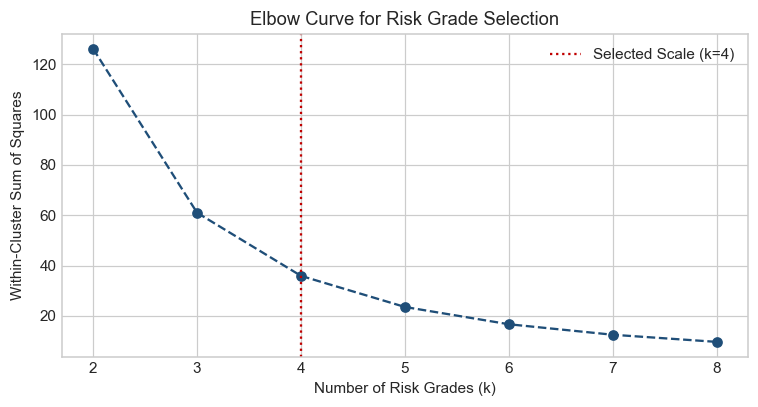


XGBOOST + K-MEANS RISK GRADE SCALE (DEVELOPMENT SET):


,Risk_Grade,Risk_Grade_Name,Dev_Accounts,Min_PPGD,Max_PPGD,Mean_Model_PPGD,Assigned_Grade_PPGD,Observed_Rate
0,1,Low Risk,34483,0.12%,6.33%,2.44%,1.82%,1.82%
1,2,Moderate Risk,9740,6.33%,16.91%,10.22%,10.70%,10.70%
2,3,High Risk,3554,16.91%,35.26%,23.60%,27.74%,27.74%
3,4,Very High Risk,1061,35.27%,86.12%,46.95%,62.87%,62.87%


In [ ]:
champion_model = tuned_models["XGBoost"]

keep_cols = ["account_id", "default_quarter", "default_year", "current_balance", "current_ltv", target]
dev_scored  = dev_df[keep_cols].copy()
test_scored = test_df[keep_cols].copy()
oot_scored  = oot_df[keep_cols].copy()

dev_scored["PPGD"] = restore_population_prior(
    champion_model.predict_proba(X_dev_prep)[:, 1], TARGET_TRAIN_RATE, observed_dev_rate
)
test_scored["PPGD"] = restore_population_prior(
    champion_model.predict_proba(X_test_prep)[:, 1], TARGET_TRAIN_RATE, observed_dev_rate
)
oot_scored["PPGD"] = restore_population_prior(
    champion_model.predict_proba(X_oot_prep)[:, 1], TARGET_TRAIN_RATE, observed_dev_rate
)

# Elbow curve on Development PPGDs
inertia = []
k_range = range(2, 9)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(dev_scored[["PPGD"]])
    inertia.append(km.inertia_)

plt.figure(figsize=(7, 3.8))
plt.plot(k_range, inertia, marker="o", linestyle="--", color="#1f4e78")
plt.axvline(x=4, color="#c00000", linestyle=":", label="Selected Scale (k=4)")
plt.title("Elbow Curve for Risk Grade Selection")
plt.xlabel("Number of Risk Grades (k)")
plt.ylabel("Within-Cluster Sum of Squares")
plt.xticks(k_range)
plt.legend()
plt.tight_layout()
plt.show()

# Fit 4-Grade K-Means on Development PPGDs and apply rules to Test and OOT
N_GRADES = 4
kmeans_grader = KMeans(n_clusters=N_GRADES, random_state=42, n_init=20)
kmeans_grader.fit(dev_scored[["PPGD"]])

sorted_clusters = np.argsort(kmeans_grader.cluster_centers_.flatten())
cluster_map = {int(old_c): int(new_g + 1) for new_g, old_c in enumerate(sorted_clusters)}
grade_names = {
    1: "Low Risk",
    2: "Moderate Risk",
    3: "High Risk",
    4: "Very High Risk",
}

for df_sample in [dev_scored, test_scored, oot_scored]:
    df_sample["Risk_Grade"] = pd.Series(kmeans_grader.predict(df_sample[["PPGD"]])).map(cluster_map).values
    df_sample["Risk_Grade_Name"] = df_sample["Risk_Grade"].map(grade_names)

# Assign empirical Development default rate (LRADR) to each grade
grade_pooled_map = dev_scored.groupby("Risk_Grade")[target].mean().to_dict()
for df_sample in [dev_scored, test_scored, oot_scored]:
    df_sample["Grade_PPGD"] = df_sample["Risk_Grade"].map(grade_pooled_map)

grade_summary = dev_scored.groupby(["Risk_Grade", "Risk_Grade_Name"]).agg(
    Dev_Accounts=(target, "count"),
    Min_PPGD=("PPGD", "min"),
    Max_PPGD=("PPGD", "max"),
    Mean_Model_PPGD=("PPGD", "mean"),
    Assigned_Grade_PPGD=("Grade_PPGD", "mean"),
    Observed_Rate=(target, "mean")
).reset_index()

print("\nXGBOOST + K-MEANS RISK GRADE SCALE (DEVELOPMENT SET):")
display(grade_summary.style.format({
    "Min_PPGD": "{:.2%}", "Max_PPGD": "{:.2%}",
    "Mean_Model_PPGD": "{:.2%}", "Assigned_Grade_PPGD": "{:.2%}", "Observed_Rate": "{:.2%}"
}))

# Save artefacts and preprocessed matrices
joblib.dump(preprocessor_std, "../data/model_artefacts/global_preprocessor.pkl")
joblib.dump(champion_model, "../data/model_artefacts/champion_xgboost_model.pkl")
joblib.dump(kmeans_grader, "../data/model_artefacts/kmeans_risk_grader.pkl")

ohe_cats = list(preprocessor_std.named_transformers_["cat"].named_steps["ohe"].get_feature_names_out(cat_cols))
feature_names_out = num_cols + ohe_cats

pd.DataFrame(X_dev_prep, columns=feature_names_out).to_csv("../data/model_artefacts/X_dev_prep.csv", index=False)
pd.DataFrame(X_test_prep, columns=feature_names_out).to_csv("../data/model_artefacts/X_test_prep.csv", index=False)
pd.DataFrame(X_oot_prep, columns=feature_names_out).to_csv("../data/model_artefacts/X_oot_prep.csv", index=False)

dev_scored.to_csv("../data/model_artefacts/dev_scored_predictions.csv", index=False)
test_scored.to_csv("../data/model_artefacts/test_scored_predictions.csv", index=False)
oot_scored.to_csv("../data/model_artefacts/oot_scored_predictions.csv", index=False)